# Olist E-Commerce Business Analytics
### A Business Analyst Engagement — Sales, Customer, and Operations Analysis

**Dataset:** Brazilian E-Commerce Public Dataset by Olist (real, anonymized transactional data, 2016–2018)
99,441 orders · 99,441 customers · 3,095 sellers · 32,951 products · 8,000 marketing leads

**Engagement structure** (modeled as a 4-week BA project):
- **Week 1 — Data Foundation:** build a relational database, audit data quality, define KPIs
- **Week 2 — Sales & Business Performance:** revenue trends, category mix, geography, payments
- **Week 3 — Customer Analytics:** RFM segmentation, retention, customer value
- **Week 4 — Operations & Satisfaction:** delivery performance, seller scorecards, marketing funnel, and final recommendations

All queries live as standalone, reusable `.sql` files in `/sql` — this notebook loads and runs them rather than hard-coding SQL inline, matching how a BA would work in a real analytics stack.

---


## Week 1 — Data Foundation

### 1.1 Setup

In [1]:
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 10
sns.set_style('whitegrid')
PALETTE = ['#2E5EAA','#E8743B','#19A979','#ED4A7B','#945ECF','#13A4B4','#F2B134','#7A7A7A']

conn = sqlite3.connect('olist.db')

def run_sql(filename):
    with open(f'sql/{filename}') as f:
        query = f.read()
    return pd.read_sql(query, conn)

print("Connected to database.")

Connected to database.


### 1.2 Database Overview

In [2]:
tables = pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", conn)['name'].tolist()
overview = []
for t in tables:
    n = pd.read_sql(f"SELECT COUNT(*) c FROM {t}", conn)['c'][0]
    overview.append({'table': t, 'row_count': n})
overview_df = pd.DataFrame(overview).sort_values('row_count', ascending=False)
overview_df

,table,row_count
2,order_items,112650
3,order_payments,103886
1,orders,99441
0,customers,99441
4,order_reviews,98410
5,products,32951
7,geolocation,19015
8,leads_qualified,8000
6,sellers,3095
9,leads_closed,842


**Schema summary:** `orders` is the central fact table, linking to `customers` (1 customer per order via `customer_id`, but `customer_unique_id` identifies the *person* across orders), `order_items` (line items, links to `products` and `sellers`), `order_payments`, and `order_reviews`. `geolocation` maps zip-code prefixes to coordinates. `leads_qualified`/`leads_closed` are a separate marketing-funnel dataset (seller acquisition, not customer purchases) joined in for Week 4.

### 1.3 Data Quality Audit

In [3]:
order_status = pd.read_sql("SELECT order_status, COUNT(*) c FROM orders GROUP BY order_status ORDER BY c DESC", conn)
print("Order status distribution (all-time):")
print(order_status)
print(f"\n{order_status.loc[order_status.order_status=='delivered','c'].values[0] / order_status['c'].sum()*100:.1f}% of all orders are 'delivered' — this analysis focuses on delivered orders unless stated otherwise.")

Order status distribution (all-time):
  order_status      c
0    delivered  96478
1      shipped   1107
2     canceled    625
3  unavailable    609
4     invoiced    314
5   processing    301
6      created      5
7     approved      2

97.0% of all orders are 'delivered' — this analysis focuses on delivered orders unless stated otherwise.


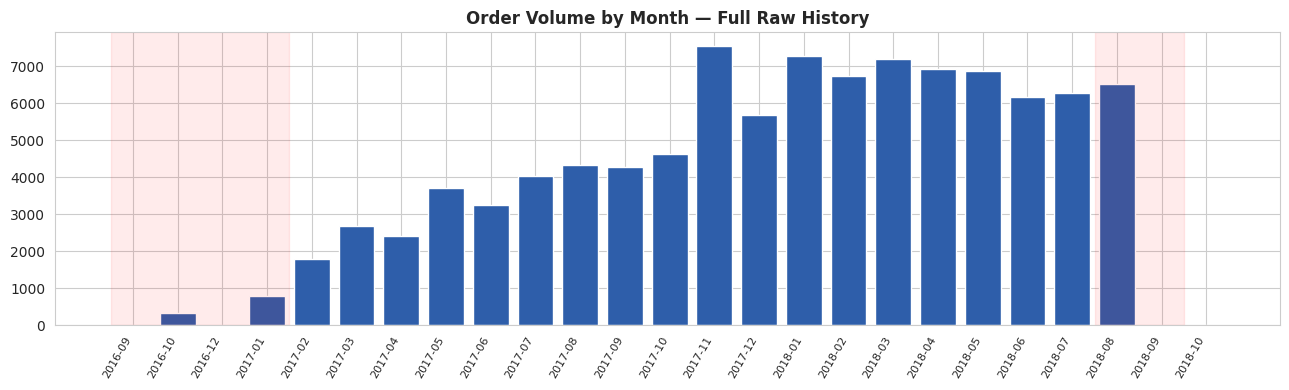

In [4]:
monthly_volume = pd.read_sql('''
    SELECT strftime('%Y-%m', order_purchase_timestamp) ym, COUNT(*) c
    FROM orders GROUP BY ym ORDER BY ym
''', conn)

fig, ax = plt.subplots(figsize=(13,4))
ax.bar(monthly_volume['ym'], monthly_volume['c'], color=PALETTE[0])
ax.set_xticklabels(monthly_volume['ym'], rotation=60, ha='right', fontsize=8)
ax.set_title('Order Volume by Month — Full Raw History', fontweight='bold')
ax.axvspan(-0.5, 3.5, color='red', alpha=0.08)
ax.axvspan(21.5, 23.5, color='red', alpha=0.08)
plt.tight_layout()
plt.savefig('figs/00_data_quality_volume.png', bbox_inches='tight')
plt.show()

**Data quality decision:** Sep–Dec 2016 (highlighted) has only ~267 orders total — clearly a soft-launch/pilot period, not representative trading activity. Sep–Oct 2018 is also a near-empty trailing tail (the data extract cuts off mid-stream). **Decision: all analysis in this notebook uses the window Jan 2017 – Aug 2018**, which is the stable, complete-month range. This kind of window decision — and documenting *why* — is exactly the judgment call a business analyst is expected to make and justify.

In [5]:
missing_report = {}
for t in ['orders','order_items','order_payments','order_reviews','products','customers']:
    df = pd.read_sql(f"SELECT * FROM {t} LIMIT 200000", conn)
    miss = df.isnull().mean()*100
    missing_report[t] = miss[miss>0].round(2).to_dict()

for t, m in missing_report.items():
    if m:
        print(f"{t}: {m}")
    else:
        print(f"{t}: no missing values")

orders: {'order_approved_at': 0.16, 'order_delivered_carrier_date': 1.79, 'order_delivered_customer_date': 2.98}
order_items: no missing values
order_payments: no missing values
order_reviews: {'review_comment_title': 88.29, 'review_comment_message': 58.67}
products: {'product_category_name': 1.85, 'product_name_lenght': 1.85, 'product_description_lenght': 1.85, 'product_photos_qty': 1.85, 'product_weight_g': 0.01, 'product_length_cm': 0.01, 'product_height_cm': 0.01, 'product_width_cm': 0.01, 'product_category_name_english': 1.89}
customers: no missing values


**Key gaps found:** `order_reviews` has missing comment titles/messages (expected — most customers rate without writing a comment). `products` has a small number of missing category names/dimensions (~1-2%, will be labeled 'unknown' rather than dropped, to avoid losing valid revenue rows). No missing values in the core transactional fields (`orders`, `order_items`, `order_payments`) — the transactional backbone of the data is clean.

### 1.4 KPI Definitions

To keep the rest of the analysis unambiguous, here are the KPIs used throughout, matching real e-commerce/BA terminology:

| KPI | Definition |
|---|---|
| **GMV** (Gross Merchandise Value) | Sum of item price + freight, for delivered orders |
| **AOV** (Average Order Value) | GMV ÷ number of distinct delivered orders |
| **Repeat Rate** | % of unique customers (`customer_unique_id`) with >1 delivered order |
| **RFM** | Recency (days since last order), Frequency (order count), Monetary (total spend) |
| **On-time delivery** | `order_delivered_customer_date` ≤ `order_estimated_delivery_date` |
| **MQL→Close Conversion** | % of Marketing Qualified Leads that became a signed seller |


## Week 2 — Sales & Business Performance

### 2.1 Revenue Trend

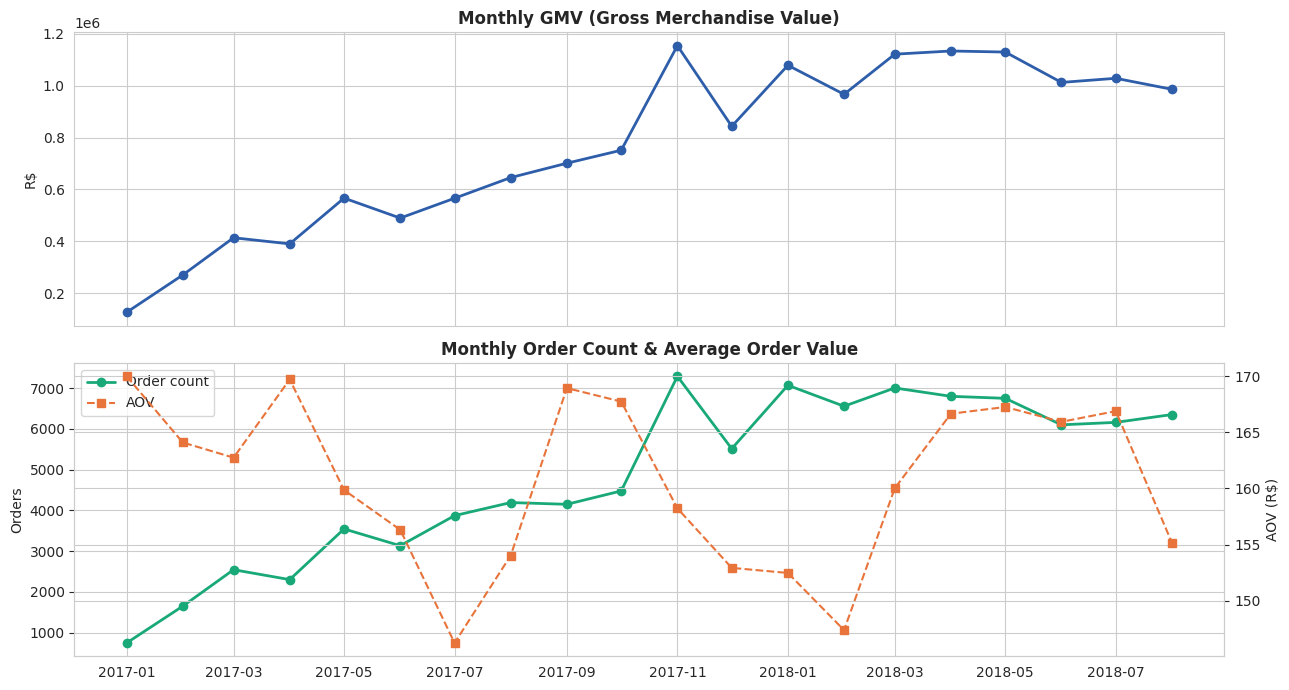

Total GMV (Jan 2017 - Aug 2018): R$ 15,373,120.01
Total delivered orders: 96,211
Overall AOV: R$ 159.79


In [6]:
rev = run_sql('01_monthly_revenue_trend.sql')
rev['year_month'] = pd.to_datetime(rev['year_month'])

fig, axes = plt.subplots(2,1, figsize=(13,7), sharex=True)
axes[0].plot(rev['year_month'], rev['gmv'], color=PALETTE[0], marker='o', lw=2)
axes[0].set_title('Monthly GMV (Gross Merchandise Value)', fontweight='bold')
axes[0].set_ylabel('R$')

axes[1].plot(rev['year_month'], rev['order_count'], color=PALETTE[2], marker='o', lw=2, label='Order count')
ax2 = axes[1].twinx()
ax2.plot(rev['year_month'], rev['avg_order_value'], color=PALETTE[1], marker='s', lw=1.5, ls='--', label='AOV')
axes[1].set_title('Monthly Order Count & Average Order Value', fontweight='bold')
axes[1].set_ylabel('Orders'); ax2.set_ylabel('AOV (R$)')
lines1,labels1 = axes[1].get_legend_handles_labels(); lines2,labels2 = ax2.get_legend_handles_labels()
axes[1].legend(lines1+lines2, labels1+labels2, loc='upper left')
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.xticks(rotation=60)
plt.tight_layout()
plt.savefig('figs/01_revenue_trend.png', bbox_inches='tight')
plt.show()

total_gmv = rev['gmv'].sum()
print(f"Total GMV (Jan 2017 - Aug 2018): R$ {total_gmv:,.2f}")
print(f"Total delivered orders: {rev['order_count'].sum():,}")
print(f"Overall AOV: R$ {total_gmv/rev['order_count'].sum():.2f}")

**Observation:** GMV grows steadily through 2017, with a pronounced spike in **November 2017** — this coincides with Black Friday, confirming the business captures major seasonal shopping events. Growth continues into early 2018 before **plateauing** from March 2018 onward — order count stabilizes and even dips slightly, while AOV stays roughly flat. This plateau is the single most important business signal in the whole dataset: **growth is not compounding indefinitely; it's a candidate for stagnation and requires the customer-retention diagnosis in Week 3.**

### 2.2 Category Performance

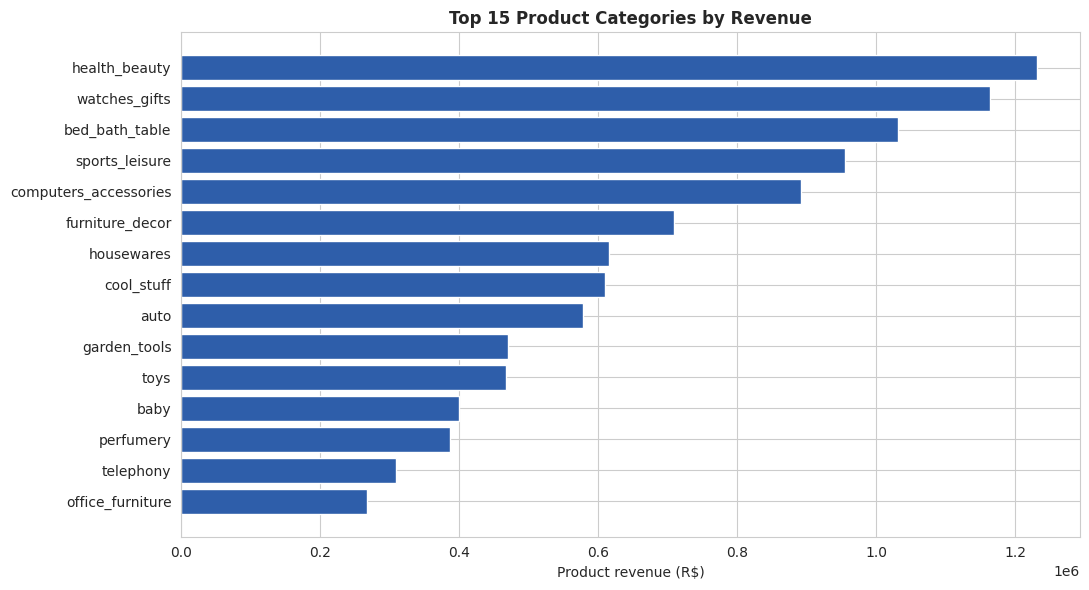

Top 15 categories account for 76.4% of total product revenue

Lowest-rated categories (min 20 orders):
             category  order_count  avg_review_score
  diapers_and_hygiene           24              3.33
     office_furniture         1248              3.52
       home_comfort_2           24              3.63
      fixed_telephony          207              3.75
fashion_male_clothing          105              3.78


In [7]:
cat = run_sql('02_category_performance.sql')
cat = cat[cat['order_count']>=20]  # drop tiny/noisy categories
top15 = cat.nlargest(15,'product_revenue')

fig, ax = plt.subplots(figsize=(11,6))
bars = ax.barh(top15['category'][::-1], top15['product_revenue'][::-1], color=PALETTE[0])
ax.set_title('Top 15 Product Categories by Revenue', fontweight='bold')
ax.set_xlabel('Product revenue (R$)')
plt.tight_layout()
plt.savefig('figs/02_top_categories.png', bbox_inches='tight')
plt.show()

print(f"Top 15 categories account for {top15['product_revenue'].sum()/cat['product_revenue'].sum()*100:.1f}% of total product revenue")
print(f"\nLowest-rated categories (min 20 orders):")
print(cat.nsmallest(5,'avg_review_score')[['category','order_count','avg_review_score']].to_string(index=False))

**Observation:** Revenue is led by **health & beauty, watches/gifts, bed/bath/table, sports/leisure and computer accessories** — a fairly diversified catalog rather than dependence on one hero category. However, review scores vary meaningfully by category; a few categories combine decent volume with **below-average satisfaction**, which is worth cross-referencing against delivery performance in Week 4 before assuming it's a product-quality issue.

### 2.3 Geographic Analysis

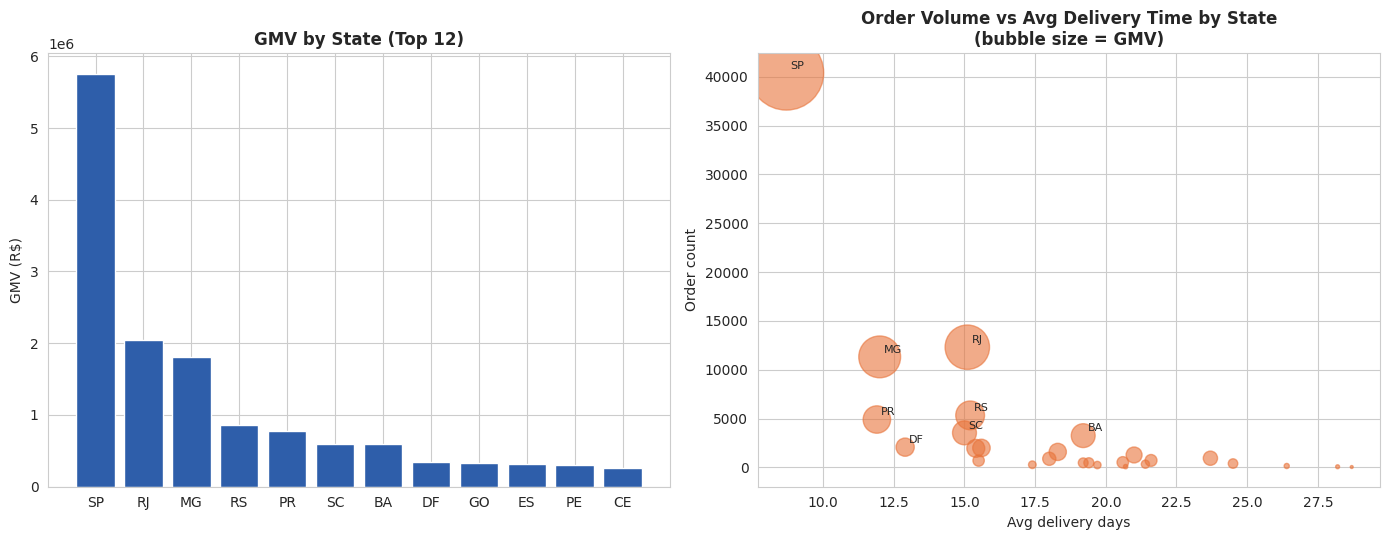

Fastest-delivery states:
 state  avg_delivery_days  order_count
   SP                8.7        40406
   PR               11.9         4903
   MG               12.0        11319

Slowest-delivery states:
 state  avg_delivery_days  order_count
   RR               28.7           40
   AP               28.2           67
   AM               26.4          145


In [8]:
state = run_sql('03_state_analysis.sql')

fig, axes = plt.subplots(1,2, figsize=(14,5.5))
top12 = state.nlargest(12,'gmv')
axes[0].bar(top12['state'], top12['gmv'], color=PALETTE[0])
axes[0].set_title('GMV by State (Top 12)', fontweight='bold')
axes[0].set_ylabel('GMV (R$)')

axes[1].scatter(state['avg_delivery_days'], state['order_count'], s=state['gmv']/2000, alpha=0.6, color=PALETTE[1])
for _,r in state.nlargest(8,'order_count').iterrows():
    axes[1].annotate(r['state'], (r['avg_delivery_days'], r['order_count']), fontsize=8, xytext=(3,3), textcoords='offset points')
axes[1].set_title('Order Volume vs Avg Delivery Time by State\n(bubble size = GMV)', fontweight='bold')
axes[1].set_xlabel('Avg delivery days'); axes[1].set_ylabel('Order count')
plt.tight_layout()
plt.savefig('figs/03_geography.png', bbox_inches='tight')
plt.show()

print("Fastest-delivery states:\n", state.nsmallest(3,'avg_delivery_days')[['state','avg_delivery_days','order_count']].to_string(index=False))
print("\nSlowest-delivery states:\n", state.nlargest(3,'avg_delivery_days')[['state','avg_delivery_days','order_count']].to_string(index=False))

**Observation:** **São Paulo (SP)** dominates both order volume and GMV by a wide margin — expected, as it's Brazil's largest metro and closest to most sellers — and also has the **fastest delivery times**. States in the North/Northeast (e.g. remote regions) show **substantially longer delivery windows**, a logistics-distance effect that becomes important context for the delivery-satisfaction analysis in Week 4.

### 2.4 Payment Behavior

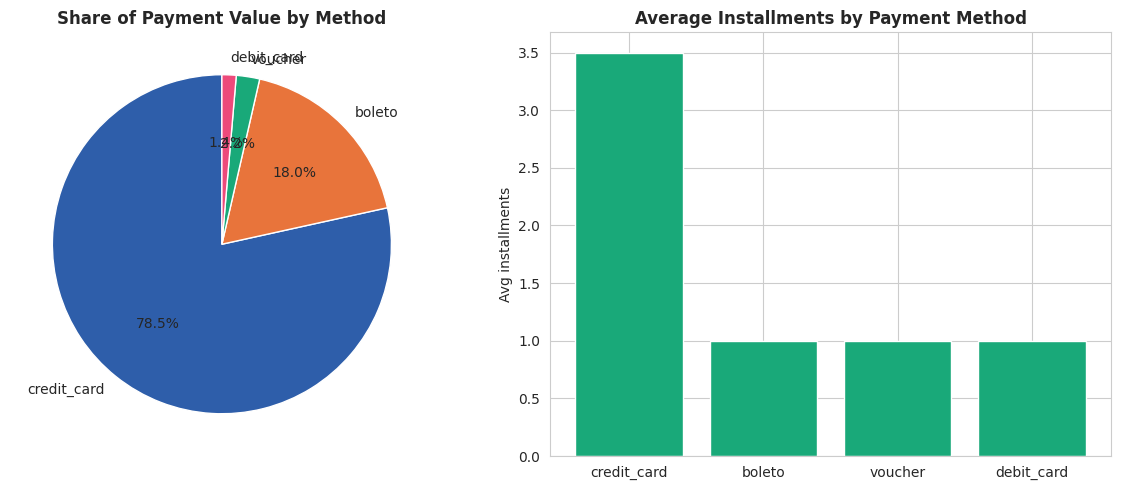

,payment_type,payment_count,avg_payment_value,avg_installments,total_payment_value
0,credit_card,74376,162.19,3.5,12063100.59
1,boleto,19140,144.32,1.0,2762300.80
2,voucher,5473,62.54,1.0,342294.66
3,debit_card,1484,140.28,1.0,208179.39


In [9]:
pay = run_sql('04_payment_behavior.sql')

fig, axes = plt.subplots(1,2, figsize=(12,5))
axes[0].pie(pay['total_payment_value'], labels=pay['payment_type'], autopct='%1.1f%%',
            colors=PALETTE[:len(pay)], startangle=90)
axes[0].set_title('Share of Payment Value by Method', fontweight='bold')

axes[1].bar(pay['payment_type'], pay['avg_installments'], color=PALETTE[2])
axes[1].set_title('Average Installments by Payment Method', fontweight='bold')
axes[1].set_ylabel('Avg installments')
plt.tight_layout()
plt.savefig('figs/04_payments.png', bbox_inches='tight')
plt.show()
pay

**Observation:** **Credit card dominates** (~78% of payment value) with an average of **3.5 installments** — a strong signal that Brazilian consumers use Olist's installment financing heavily, which likely supports higher AOV than a cash-only market would allow. Boleto (bank slip, a cash-equivalent instrument common in Brazil) is a distant second. This has a direct **finance/ops implication**: cash flow timing depends heavily on installment schedules, not just gross sales.

### 2.5 Order Fulfillment Funnel

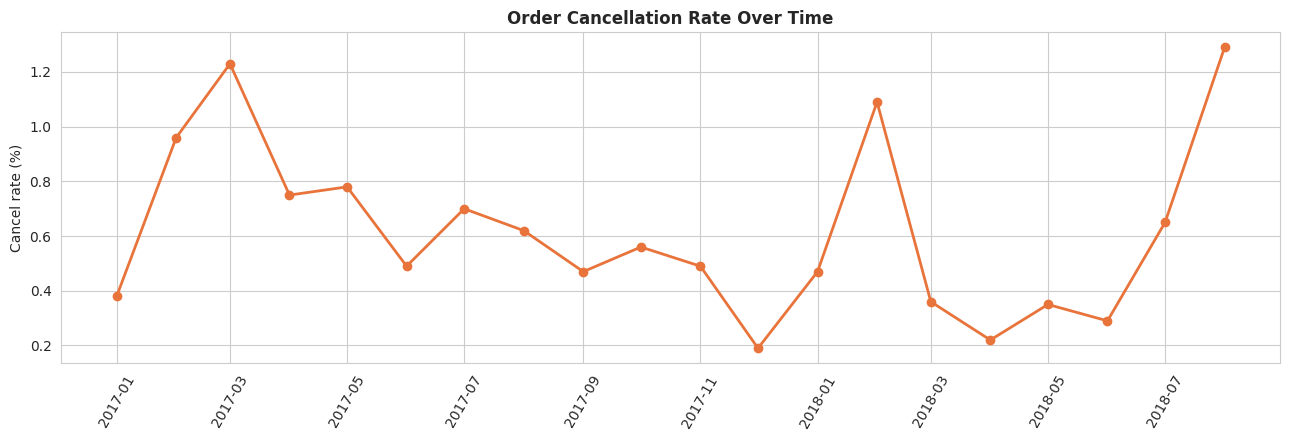

Overall cancellation rate: 0.59%


In [10]:
funnel = run_sql('10_order_status_funnel.sql')
funnel['year_month'] = pd.to_datetime(funnel['year_month'])

fig, ax = plt.subplots(figsize=(13,4.5))
ax.plot(funnel['year_month'], funnel['cancel_rate_pct'], color=PALETTE[1], marker='o', lw=2)
ax.set_title('Order Cancellation Rate Over Time', fontweight='bold')
ax.set_ylabel('Cancel rate (%)')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.xticks(rotation=60)
plt.tight_layout()
plt.savefig('figs/05_cancellation_trend.png', bbox_inches='tight')
plt.show()

print(f"Overall cancellation rate: {funnel['canceled'].sum()/funnel['total_orders'].sum()*100:.2f}%")

**Observation:** Cancellation rate is low overall (~0.6%) and doesn't show a worsening trend — order fulfillment operations are stable. This rules out "broken checkout/fulfillment process" as an explanation for the growth plateau seen in 2.1; the issue is more likely on the demand/retention side, which Week 3 investigates directly.

## Week 3 — Customer Analytics

Week 2 found a growth plateau from March 2018 onward. This section asks: **is the business retaining the customers it acquires, or constantly replacing churned customers with new ones?**

### 3.1 Repeat Purchase Rate

In [11]:
repeat = run_sql('06_repeat_purchase_rate.sql')
repeat

,total_customers,one_time_customers,repeat_customers,repeat_rate_pct
0,93104,90315,2789,3.0


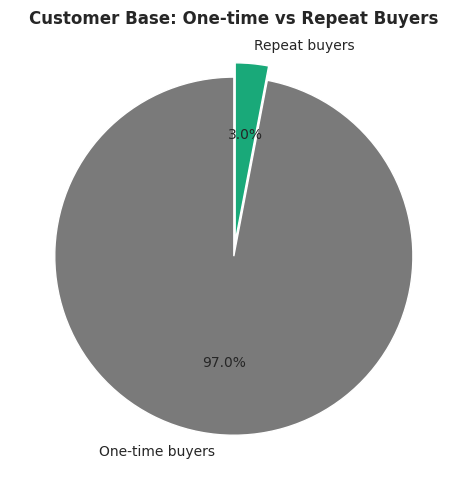

In [12]:
fig, ax = plt.subplots(figsize=(6,5))
sizes = [repeat['one_time_customers'][0], repeat['repeat_customers'][0]]
ax.pie(sizes, labels=['One-time buyers','Repeat buyers'], autopct='%1.1f%%',
       colors=[PALETTE[7], PALETTE[2]], startangle=90, explode=(0,0.08))
ax.set_title('Customer Base: One-time vs Repeat Buyers', fontweight='bold')
plt.tight_layout()
plt.savefig('figs/06_repeat_rate.png', bbox_inches='tight')
plt.show()

**This is the headline finding of the whole analysis: only ~3% of customers ever place a second order.** For an e-commerce marketplace, this is a low repeat rate — it means growth is almost entirely dependent on **new customer acquisition**, not on building a loyal base, which directly explains the growth plateau in Week 2 (once acquisition growth slows, so does overall growth, because there's very little repeat-revenue cushion underneath it).

### 3.2 RFM Segmentation

In [13]:
rfm = run_sql('05_rfm_base.sql')
rfm['last_purchase_date'] = pd.to_datetime(rfm['last_purchase_date'])
snapshot_date = pd.Timestamp('2018-09-01')
rfm['recency_days'] = (snapshot_date - rfm['last_purchase_date']).dt.days

# score 1 (worst) to 4 (best) via quartiles
rfm['R_score'] = pd.qcut(rfm['recency_days'], 4, labels=[4,3,2,1]).astype(int)
rfm['F_score'] = rfm['frequency'].apply(lambda x: 4 if x>=3 else (3 if x==2 else 1))
rfm['M_score'] = pd.qcut(rfm['monetary'].rank(method='first'), 4, labels=[1,2,3,4]).astype(int)
rfm['RFM_sum'] = rfm['R_score'] + rfm['F_score'] + rfm['M_score']

def segment(row):
    if row['frequency'] >= 2 and row['R_score']>=3:
        return 'Loyal / Repeat'
    elif row['RFM_sum']>=10:
        return 'Champions'
    elif row['R_score']<=2 and row['RFM_sum']<7:
        return 'At Risk / Lost'
    elif row['R_score']>=3:
        return 'Recent, Low-value'
    else:
        return 'Needs Attention'

rfm['segment'] = rfm.apply(segment, axis=1)
seg_summary = rfm.groupby('segment').agg(customers=('customer_unique_id','count'), avg_monetary=('monetary','mean'), total_monetary=('monetary','sum')).sort_values('total_monetary', ascending=False)
seg_summary['pct_customers'] = (seg_summary['customers']/seg_summary['customers'].sum()*100).round(1)
seg_summary['pct_revenue'] = (seg_summary['total_monetary']/seg_summary['total_monetary'].sum()*100).round(1)
seg_summary.round(2)

,customers,avg_monetary,total_monetary,pct_customers,pct_revenue
segment,,,,,
"Recent, Low-value",45141,161.68,7298615.19,48.5,47.5
At Risk / Lost,39935,129.63,5176897.91,42.9,33.7
Needs Attention,6449,370.44,2388981.30,6.9,15.5
Loyal / Repeat,1539,314.91,484641.28,1.7,3.2
Champions,40,599.61,23984.33,0.0,0.2


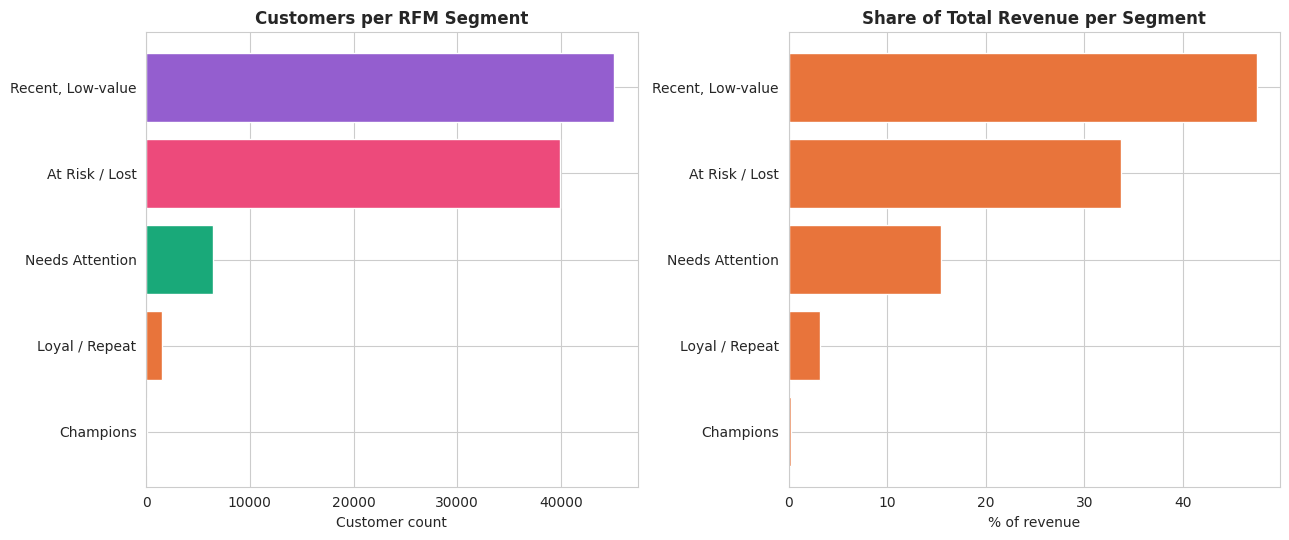

In [14]:
fig, axes = plt.subplots(1,2, figsize=(13,5.5))
seg_summary_sorted = seg_summary.sort_values('customers', ascending=True)
axes[0].barh(seg_summary_sorted.index, seg_summary_sorted['customers'], color=PALETTE[:len(seg_summary_sorted)])
axes[0].set_title('Customers per RFM Segment', fontweight='bold')
axes[0].set_xlabel('Customer count')

axes[1].barh(seg_summary_sorted.index, seg_summary_sorted['pct_revenue'], color=PALETTE[1])
axes[1].set_title('Share of Total Revenue per Segment', fontweight='bold')
axes[1].set_xlabel('% of revenue')
plt.tight_layout()
plt.savefig('figs/07_rfm_segments.png', bbox_inches='tight')
plt.show()

**Observation:** The **"Recent, Low-value"** and **"At Risk / Lost"** segments dominate the customer base by count — a direct reflection of the 3% repeat rate. **"Loyal / Repeat"** customers are a small group but disproportionately valuable per capita, confirming the classic 80/20-style pattern even in a low-retention business. The clear strategic lever here is converting more first-time buyers into a second purchase — even a modest improvement in repeat rate would meaningfully change the revenue mix.

### 3.3 Cohort Retention Analysis

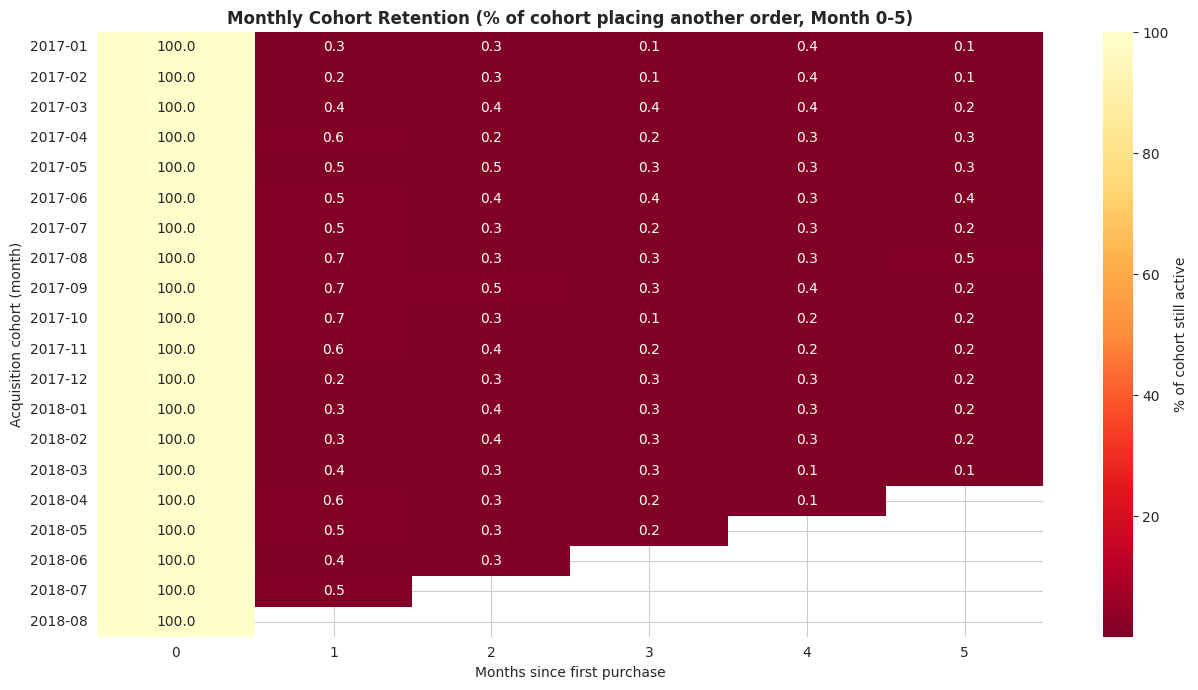

In [15]:
cohort_data = run_sql('05_rfm_base.sql')
orders_full = pd.read_sql('''
    SELECT c.customer_unique_id, o.order_purchase_timestamp
    FROM orders o JOIN customers c ON o.customer_id=c.customer_id
    WHERE o.order_status='delivered'
      AND o.order_purchase_timestamp >= '2017-01-01' AND o.order_purchase_timestamp < '2018-09-01'
''', conn)
orders_full['order_purchase_timestamp'] = pd.to_datetime(orders_full['order_purchase_timestamp'])
orders_full['order_month'] = orders_full['order_purchase_timestamp'].dt.to_period('M')

first_purchase = orders_full.groupby('customer_unique_id')['order_month'].min().rename('cohort_month')
orders_full = orders_full.join(first_purchase, on='customer_unique_id')
orders_full['cohort_index'] = (orders_full['order_month'] - orders_full['cohort_month']).apply(lambda x: x.n)

cohort_counts = orders_full.groupby(['cohort_month','cohort_index'])['customer_unique_id'].nunique().reset_index()
cohort_pivot = cohort_counts.pivot(index='cohort_month', columns='cohort_index', values='customer_unique_id')
cohort_size = cohort_pivot.iloc[:,0]
retention = cohort_pivot.divide(cohort_size, axis=0)*100

fig, ax = plt.subplots(figsize=(13,7))
sns.heatmap(retention.iloc[:, :6], annot=True, fmt='.1f', cmap='YlOrRd_r', ax=ax,
            cbar_kws={'label':'% of cohort still active'})
ax.set_title('Monthly Cohort Retention (% of cohort placing another order, Month 0-5)', fontweight='bold')
ax.set_xlabel('Months since first purchase'); ax.set_ylabel('Acquisition cohort (month)')
plt.tight_layout()
plt.savefig('figs/08_cohort_retention.png', bbox_inches='tight')
plt.show()

**Observation:** The cohort heatmap makes the retention problem visually unmistakable — **Month-1 retention is under ~1-2% for essentially every cohort**, and it decays further from there. This isn't a one-off cohort issue or a seasonal blip; it's structural and consistent across the entire 20-month history. For a business analyst's recommendation, this reframes the priority: **marketing spend to acquire new customers is working (Week 2 shows real GMV growth), but there is close to zero post-purchase retention program in effect** — a clear, high-leverage gap to flag to leadership (e.g. no observed win-back email flow, loyalty incentive, or second-purchase discount pattern in the data).

### 3.4 High-Value Customer Profile

In [16]:
top_customers = rfm.nlargest(15, 'monetary')[['customer_unique_id','frequency','monetary','recency_days','segment']]
top_customers['monetary'] = top_customers['monetary'].round(2)
top_customers

,customer_unique_id,frequency,monetary,recency_days,segment
3716,0a0a92112bd4c708ca5fde585afaa872,1,13664.08,336,Needs Attention
79420,da122df9eeddfedc1dc1f5349a1a690c,2,7571.63,517,Needs Attention
43051,763c8b1c9c68a0229c42c9fc6f662b93,1,7274.88,47,"Recent, Low-value"
80246,dc4802a71eae9be1dd28f5d788ceb526,1,6929.31,565,At Risk / Lost
25360,459bef486812aa25204be022145caa62,1,6922.21,37,"Recent, Low-value"
92831,ff4159b92c40ebe40454e3e6a7c35ed6,1,6726.66,464,At Risk / Lost
23341,4007669dec559734d6f53e029e360987,1,6081.54,280,Needs Attention
86913,eebb5dda148d3893cdaf5b5ca3040ccb,1,4764.34,500,At Risk / Lost
26562,48e1ac109decbb87765a3eade6854098,1,4681.78,70,"Recent, Low-value"
72934,c8460e4251689ba205045f3ea17884a1,4,4655.88,23,Loyal / Repeat


**Observation:** Even the very top customers by spend are mostly **single large orders**, not high-frequency repeat buyers — reinforcing that the current "high value" customer is defined by *order size*, not *loyalty*. A genuine VIP/loyalty program targeting the small existing repeat-buyer segment (Section 3.2) is likely to have a better ROI than chasing bigger one-off baskets.

## Week 4 — Operations, Satisfaction & Marketing Funnel

### 4.1 Delivery Performance vs Customer Satisfaction

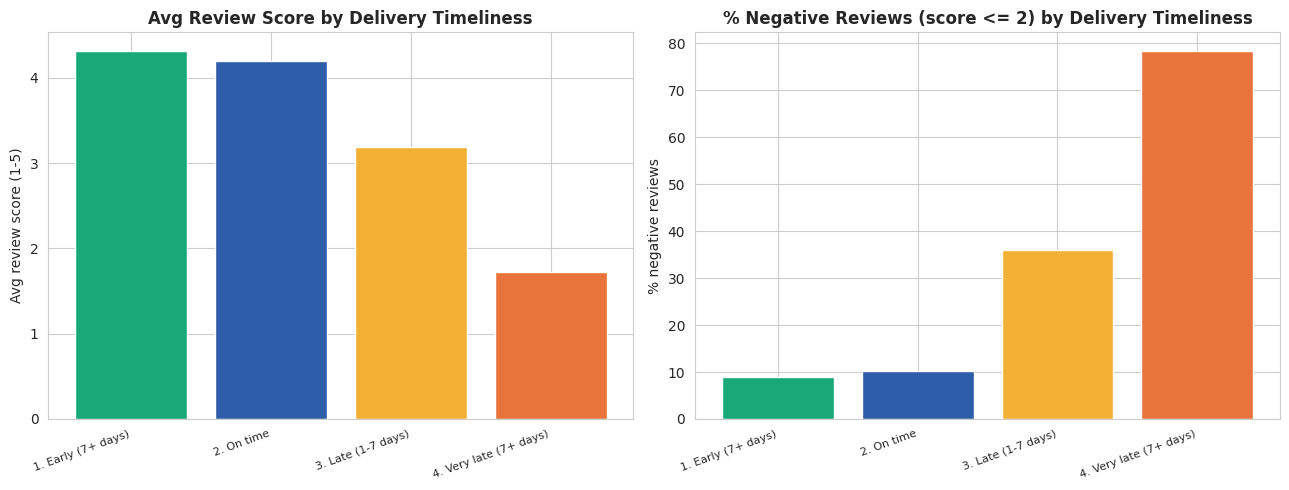

,delivery_bucket,order_count,avg_review_score,pct_negative_reviews
0,1. Early (7+ days),70493,4.319,8.91
1,2. On time,17210,4.203,10.16
2,3. Late (1-7 days),4390,3.185,36.04
3,4. Very late (7+ days),3240,1.728,78.43


In [17]:
delivery = run_sql('07_delivery_vs_satisfaction.sql')

fig, axes = plt.subplots(1,2, figsize=(13,5))
colors = [PALETTE[2],PALETTE[0],PALETTE[6],PALETTE[1]]
axes[0].bar(delivery['delivery_bucket'], delivery['avg_review_score'], color=colors)
axes[0].set_title('Avg Review Score by Delivery Timeliness', fontweight='bold')
axes[0].set_ylabel('Avg review score (1-5)')
axes[0].set_xticklabels(delivery['delivery_bucket'], rotation=20, ha='right', fontsize=8)

axes[1].bar(delivery['delivery_bucket'], delivery['pct_negative_reviews'], color=colors)
axes[1].set_title('% Negative Reviews (score <= 2) by Delivery Timeliness', fontweight='bold')
axes[1].set_ylabel('% negative reviews')
axes[1].set_xticklabels(delivery['delivery_bucket'], rotation=20, ha='right', fontsize=8)
plt.tight_layout()
plt.savefig('figs/09_delivery_satisfaction.png', bbox_inches='tight')
plt.show()
delivery

**This is the strongest operational finding in the dataset.** Average review score falls from **4.32 (delivered 7+ days early)** to **1.73 (delivered more than a week late)** — a drop of over 2.5 points on a 5-point scale. The share of negative reviews (score ≤2) jumps from **~9% when on time to ~78% when very late**. Delivery lateness is, by a wide margin, the single strongest driver of dissatisfaction visible in this data — **more impactful than product category, price, or seller identity**. This is a natural, high-confidence recommendation: investment in delivery-estimate accuracy and logistics reliability will very likely move satisfaction (and by extension, the weak repeat-purchase rate from Week 3) more than almost any other lever.

### 4.2 Seller Scorecards

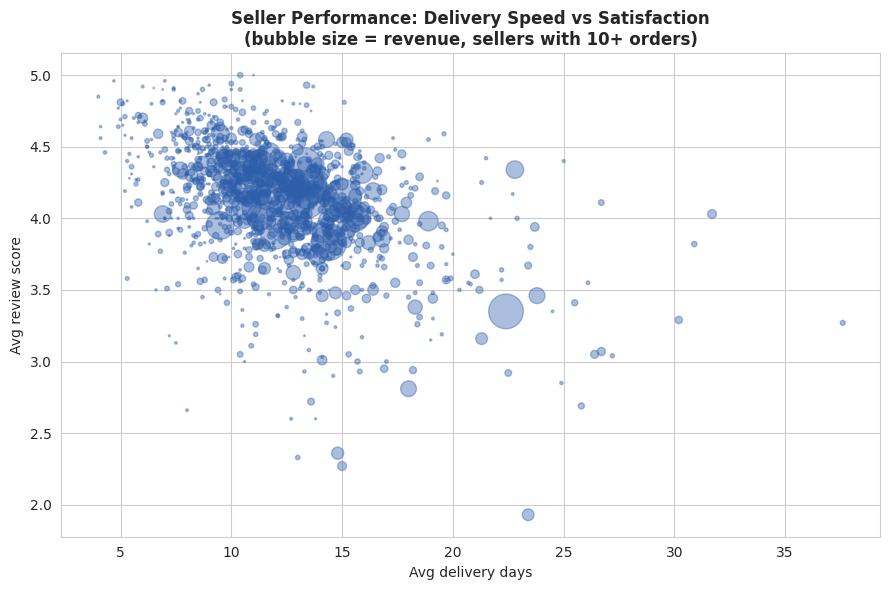

Top 10 sellers by revenue:
                       seller_id seller_state  order_count  total_revenue  avg_delivery_days  avg_review_score
4869f7a5dfa277a7dca6462dcf3b52b2           SP         1124      226987.93               15.0              4.14
53243585a1d6dc2643021fd1853d8905           BA          348      217940.44               13.4              4.13
4a3ca9315b744ce9f8e9374361493884           SP         1772      198134.62               14.4              3.83
fa1c13f2614d7b5c4749cbc52fecda94           SP          578      190917.14               13.3              4.37
7c67e1448b00f6e969d365cea6b010ab           SP          973      187576.91               22.4              3.35
7e93a43ef30c4f03f38b393420bc753a           SP          318      164582.49               11.3              4.36
da8622b14eb17ae2831f4ac5b9dab84a           SP         1311      161039.57               11.2              4.08
7a67c85e85bb2ce8582c35f2203ad736           SP         1145      139888.68            

In [18]:
sellers_kpi = run_sql('08_seller_scorecard.sql')

fig, ax = plt.subplots(figsize=(9,6))
scatter = ax.scatter(sellers_kpi['avg_delivery_days'], sellers_kpi['avg_review_score'],
                      s=sellers_kpi['total_revenue']/300, alpha=0.4, color=PALETTE[0])
ax.set_title('Seller Performance: Delivery Speed vs Satisfaction\n(bubble size = revenue, sellers with 10+ orders)', fontweight='bold')
ax.set_xlabel('Avg delivery days'); ax.set_ylabel('Avg review score')
plt.tight_layout()
plt.savefig('figs/10_seller_scatter.png', bbox_inches='tight')
plt.show()

print("Top 10 sellers by revenue:")
print(sellers_kpi.nlargest(10,'total_revenue')[['seller_id','seller_state','order_count','total_revenue','avg_delivery_days','avg_review_score']].to_string(index=False))
print("\nBottom 10 sellers by review score (min 10 orders):")
print(sellers_kpi.nsmallest(10,'avg_review_score')[['seller_id','seller_state','order_count','avg_delivery_days','avg_review_score']].to_string(index=False))

**Observation:** The scatter confirms the same pattern at the seller level — sellers with longer average delivery times cluster toward lower review scores. The bottom-10 sellers by review score are worth a targeted seller-performance review (potential re-training, tighter shipping SLAs, or in persistent cases, offboarding), since this dataset shows seller-level delivery speed is a controllable, seller-specific variable — not just a regional logistics constraint.

### 4.3 Marketing Funnel — Lead Conversion by Channel

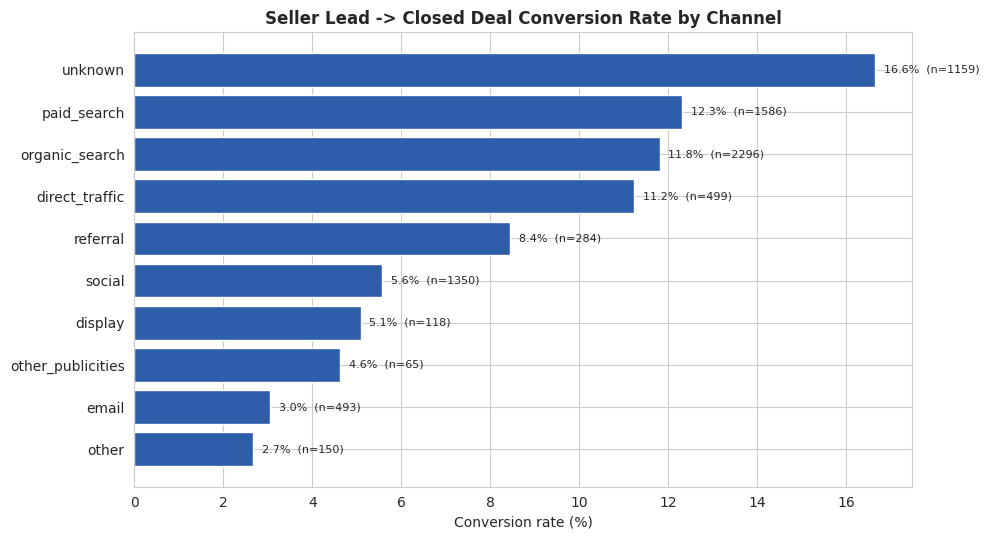

In [19]:
funnel_conv = run_sql('09_marketing_funnel_conversion.sql')
funnel_conv = funnel_conv[funnel_conv['total_leads']>=50]

fig, ax = plt.subplots(figsize=(10,5.5))
funnel_sorted = funnel_conv.sort_values('conversion_rate_pct')
bars = ax.barh(funnel_sorted['lead_origin'], funnel_sorted['conversion_rate_pct'], color=PALETTE[0])
ax.set_title('Seller Lead -> Closed Deal Conversion Rate by Channel', fontweight='bold')
ax.set_xlabel('Conversion rate (%)')
for b,v,n in zip(bars, funnel_sorted['conversion_rate_pct'], funnel_sorted['total_leads']):
    ax.text(v+0.2, b.get_y()+b.get_height()/2, f'{v:.1f}%  (n={n})', va='center', fontsize=8)
plt.tight_layout()
plt.savefig('figs/11_funnel_conversion.png', bbox_inches='tight')
plt.show()

**Note:** this funnel is about *seller* acquisition (recruiting merchants onto the marketplace), a separate funnel from customer purchases. **Paid search and organic search convert best** (~12%), while **email and other/display channels convert worst** (2-5%) despite reasonable volume — a candidate for marketing budget reallocation, though volume in the weaker channels is modest enough (n<200) that this should be treated as directional, not conclusive, without a larger sample.

## Week 4 Summary — Executive Recommendations

Bringing all four weeks together, here are the priority recommendations, ranked by expected business impact and confidence:

1. **🎯 Fix delivery reliability first.** This is the highest-confidence, highest-leverage finding in the entire analysis: late delivery is associated with a >2.5 point collapse in review score. Tightening delivery-estimate accuracy (so `order_estimated_delivery_date` is realistic) and improving logistics for slow-delivery states (Week 2.3) should be the top operational priority.

2. **🔁 Build a retention program — there currently appears to be none.** A 3% repeat-purchase rate and near-zero Month-1 cohort retention (Week 3) means the business is running almost entirely on new-customer acquisition. Even a modest post-purchase engagement flow (reminder email, second-order discount, loyalty points) targeting recent first-time buyers could materially shift the revenue mix toward the more valuable "Loyal / Repeat" segment.

3. **📦 Investigate underperforming sellers individually**, not just categories — Week 4.2 shows satisfaction issues are often seller-specific (controllable) rather than purely category-driven, so seller-level coaching/SLAs will likely outperform blanket category policies.

4. **📈 Growth is plateauing (Week 2.1) — and Week 3 explains why.** Since repeat purchasing is minimal, GMV growth is a direct function of new-customer acquisition volume. Any slowdown in acquisition spend will show up immediately in GMV, with no retention cushion to soften it. This is a structural risk worth flagging explicitly to leadership.

5. **💳 Preserve and monitor installment-based credit card payments** (78% of payment value, avg 3.5 installments) — this is core to how Brazilian consumers afford larger baskets on this platform; any friction added to this flow carries outsized risk to AOV.

**Suggested next steps for a real engagement:** run this analysis on a rolling monthly basis (not a one-off snapshot), A/B test a retention intervention against a holdout cohort, and add external cost data (fulfillment cost per order, marketing spend per channel) to convert these directional recommendations into an ROI-ranked action plan.
